# Downward camera effect


## Question
If the drone has a downward-looking camera, does it recover better when one motor suddenly loses thrust? "Better"
means fewer crashes, a smaller altitude drop, a higher lowest point and a faster recovery. Secondly: does it fly the
route more accurately?


## The task
The flights:
- 4 random curved routes (seeds 1-4, 4.4-6.8 m long, 1.0-2.5 m high)
- 5 loss levels on motor 1 (0 / 12.5 / 25 / 37.5 / 50 %), switched on when the target is halfway along the route
- PID, 6 N cap, 0.125 s motor lag, start hovering at A, 0.5 m/s

## Three sensing conditions
| Condition | What the PID uses for position and velocity | Flights |
|---|---|---|
| **perfect** | the true state, read data directly from Mujoco | 20 |
| **no_camera** | Kalman estimate from **IMU** (100 Hz) + **GPS** (5 Hz, σ = 0.3 m horizontal, 0.4 m vertical) + **barometer** (20 Hz, σ = 0.2 m) | 20 × 3 noise seeds |
| **camera** | the same estimate, plus the **downward camera** (20 Hz): height from the floor's checker pattern, ground velocity from how the image shifts | 20 × 3 noise seeds |

- **Pairing.** For each noise seed, no_camera and camera get exactly the same IMU, GPS and barometer noise, so any
  difference between them comes from the camera alone. 3 seeds show how much the result depends on noise luck.
- **Attitude** (tilt and heading) and body rates are taken as known in every condition: a good attitude estimator
  is assumed. The experiment isolates what the camera adds to position and velocity.
- **Scoring** always uses the true state, never the estimate.

**Expectation going in:** the camera should mainly improve accuracy (where the drone thinks it is). Recovery from
the fault is limited by thrust, so it may change little.

In [2]:
import json, sys
from pathlib import Path

HERE = Path(globals().get("__vsc_ipynb_file__", Path.cwd() / "camera_effect.ipynb")).resolve().parent
if not ((HERE / "experiment.py").exists() and (HERE / "sensing.py").exists()):
    raise FileNotFoundError(f"experiment.py and sensing.py not found in {HERE}: start Jupyter in this notebook's folder")
sys.path.insert(0, str(HERE))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, mujoco
import experiment as E, sensing
from x2 import config
%matplotlib inline
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
DATA = E.DATA
COND_COLOURS = {"perfect": "tab:gray", "no_camera": "tab:red", "camera": "tab:blue"}
# print("experiment folder:", HERE)

## 1. The camera sensor
A 160 × 160 px camera at the drone's feet, looking down, 90° field of view, 20 frames per second. The model's
spotlight, shadows and floor reflections are switched off in this camera's render; they moved with the drone and
confused the image processing. None of them affects the physics.

- **Height.** The floor is a regular checkerboard. The farther away it is, the more checker cycles fit in each
  pixel. The strongest frequency in the image's Fourier transform gives the distance along the camera axis;
  multiplying by cos(tilt) gives the height.
- **Ground velocity.** Phase correlation finds how far the floor moved between two frames. Both viewing rays are
  intersected with the floor using the known attitude, which removes the image motion caused by the drone's own
  rotation. A checkerboard looks the same after a shift of one square, so the search is limited to the
  neighbourhood of the shift predicted from the current velocity estimate.

### Check against the truth
The drone is placed at known heights, tilts and motions and the camera's readings are compared with them.

In [2]:
model = sensing.build_model(); data = mujoco.MjData(model); cam = sensing.DownCamera(model)
def place(p, quat=(1, 0, 0, 0)):
    data.qpos[:3] = p; data.qpos[3:7] = quat; mujoco.mj_forward(model, data)
rows = []
for tilt in (0, 10, 20):
    q = np.zeros(4); mujoco.mju_axisAngle2Quat(q, np.array([1.0, 1.0, 0]) / np.sqrt(2), np.radians(tilt))
    for h in (0.3, 0.6, 1.0, 1.5, 2.0, 2.5):
        place([0.11, -0.05, h], q); cam.prev = None
        hm = cam.measure(data, (0, 0))[0]
        rows.append({"tilt [deg]": tilt, "true height [m]": h, "camera [m]": round(hm, 3), "error [%]": round(100 * (hm - h) / h, 1)})
heights = pd.DataFrame(rows)
heights.pivot(index="true height [m]", columns="tilt [deg]", values="error [%]")

tilt [deg],0,10,20
true height [m],,,
0.3,-1.3,-5.5,-1.5
0.6,-0.8,-0.6,-0.2
1.0,-0.5,-0.3,-1.0
1.5,-0.3,-0.3,1.6
2.0,-0.2,-0.4,-0.2
2.5,-0.2,-0.5,1.0


In [3]:
rows = []
for h in (0.4, 0.6, 1.5, 2.5):
    for v in [(0.5, 0.0), (0.0, 0.5), (0.35, -0.35), (1.0, 0.0)]:
        place([0.11, -0.05, h]); cam.prev = None; cam.measure(data, (0, 0))
        place([0.11 + v[0] * sensing.CAM_PERIOD, -0.05 + v[1] * sensing.CAM_PERIOD, h])
        meas = cam.measure(data, (v[0] + 0.3, v[1] - 0.3))[1]  # prediction deliberately 0.3 m/s off
        rows.append({"height [m]": h, "true v": v, "camera v": tuple(np.round(meas, 2)),
                     "error [m/s]": round(float(np.hypot(*(meas - np.array(v)))), 3)})
cam.close()
pd.DataFrame(rows).pivot(index="true v", columns="height [m]", values="error [m/s]")

height [m],0.4,0.6,1.5,2.5
true v,,,,
"(0.0, 0.5)",0.008,0.011,0.074,0.113
"(0.35, -0.35)",0.027,0.020,0.017,0.223
"(0.5, 0.0)",0.006,0.032,0.068,0.112
"(1.0, 0.0)",0.004,0.018,0.065,0.033


- **Height** is within 2 % from 0.6 to 2.5 m, including at 10-20° of tilt. Very low (0.3 m), where only about 2
  checker squares are in view, the error grows to 5.5 %.
- **Velocity** is within about 0.03 m/s below 1 m, about 0.07 m/s at 1.5 m and up to 0.22 m/s at 2.5 m, where a
  2.5 cm step is less than one pixel. This holds even when the predicted velocity used to resolve the checkerboard
  ambiguity is 0.3 m/s off.

### What the camera sees in a flight
Saved frames (seed 0): path 3 with a 37.5 % fault at 6.58 s, the flight that came closest to the ground.

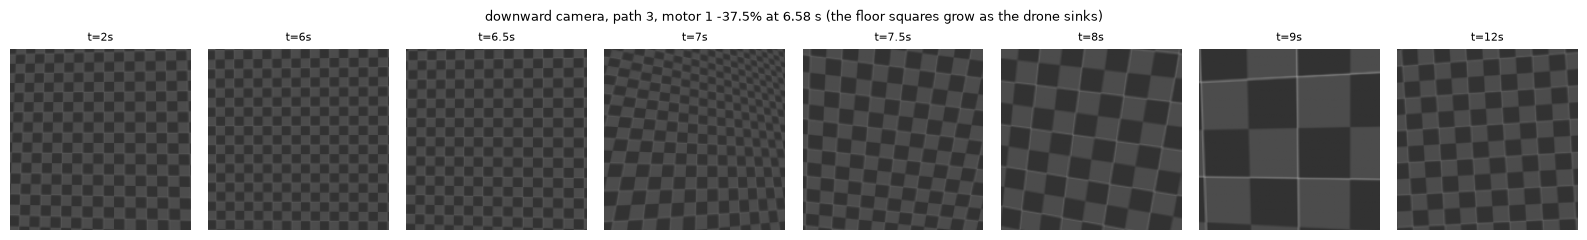

In [4]:
frames = np.load(DATA / "camera_s0_path3_loss37.5" / "frames.npz")["frames"]
times = [2, 6, 6.5, 7, 7.5, 8, 9, 12]
fig, axes = plt.subplots(1, len(times), figsize=(16, 2.4))
for ax, t in zip(axes, times):
    ax.imshow(frames[int(round(t / sensing.CAM_PERIOD))], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"t={t}s", fontsize=8); ax.axis("off")
plt.suptitle("downward camera, path 3, motor 1 -37.5% at 6.58 s (the floor squares grow as the drone sinks)", fontsize=9)
plt.tight_layout()

### How the drone reads the camera
The controller never sees an image. Each frame goes through four steps and ends up as an updated estimate of
position and velocity, which is what the PID flies on:

```
camera frame (160×160 px, 20 Hz)
   │  1. image processing: frame → height,  two frames → ground velocity (vx, vy)
   ▼
three numbers per frame
   │  2. sanity checks: plausible range, agreement with the current estimate
   ▼
Kalman filter  ◄── IMU (100 Hz), GPS (5 Hz), barometer (20 Hz)
   │  3. blends all readings, each weighted by how accurate it is
   ▼
estimated position + velocity  ──►  4. PID  ──►  motor commands
```

Nothing here is learned: it's classical image processing plus a Kalman filter. The code is in `sensing.py`
(`DownCamera.measure`, `Estimator`) and in the flight loop in `experiment.py`.

#### Step 1a: one frame → height
1. Convert the frame to grayscale.
2. Take its 2D Fourier transform. The checker floor shows up as one bright peak; its distance from the centre is the
   pattern's frequency in cycles per pixel.
3. The farther away the floor, the smaller the squares look, so the higher that frequency. With the floor's known
   pattern (squares of 0.2 m) and the camera's focal length, the frequency gives the distance along the line of
   sight.
4. Multiply by cos(tilt) to get the height straight down. Tilt comes from the drone's attitude, which every
   condition is assumed to know.

The demo below places the drone at 1.20 m and walks through these steps.

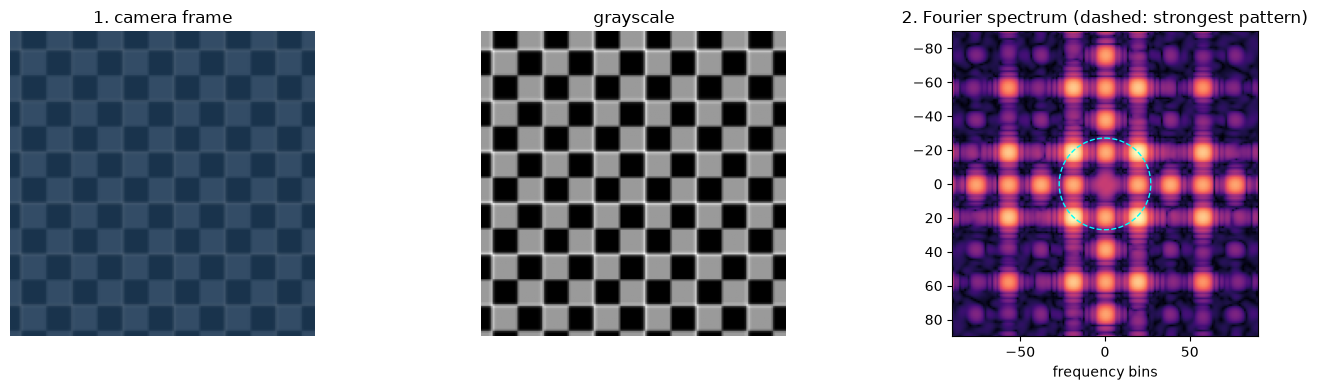

2. strongest pattern frequency : 0.0528 cycles/pixel
3. distance along line of sight: 0.0528 x 80 px / 3.536 cycles/m = 1.194 m
4. x cos(tilt) = x 1.000   -> height 1.194 m   (true 1.20 m, error -0.5 %)


In [5]:
model = sensing.build_model(); data = mujoco.MjData(model); cam = sensing.DownCamera(model)
def place(p, quat=(1, 0, 0, 0)):
    data.qpos[:3] = p; data.qpos[3:7] = quat; mujoco.mj_forward(model, data)

TRUE_H = 1.20
place([0.11, -0.05, TRUE_H])
gray, rgb = cam.render(data)
g = (gray - gray.mean()) * sensing.WINDOW
spectrum = np.fft.fftshift(np.abs(np.fft.fft2(g, s=(sensing.PAD, sensing.PAD))))
freq = sensing.checker_frequency(gray)                       # cycles per pixel
rot = data.cam_xmat[cam.cam_id].reshape(3, 3)
cos_tilt = -cam._ray(rot)[2]
distance = freq * cam.focal / cam.GROUND_FREQ                # along the line of sight
height = distance * cos_tilt

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(rgb); ax[0].set_title("1. camera frame"); ax[0].axis("off")
ax[1].imshow(gray, cmap="gray"); ax[1].set_title("grayscale"); ax[1].axis("off")
c, z = sensing.PAD // 2, 90
ax[2].imshow(np.log1p(spectrum[c - z:c + z, c - z:c + z]), cmap="magma", extent=[-z, z, z, -z])
ax[2].add_patch(plt.Circle((0, 0), freq * sensing.PAD, fill=False, color="cyan", ls="--"))
ax[2].set_title("2. Fourier spectrum (dashed: strongest pattern)"); ax[2].set_xlabel("frequency bins")
plt.tight_layout(); plt.show()
print(f"2. strongest pattern frequency : {freq:.4f} cycles/pixel")
print(f"3. distance along line of sight: {freq:.4f} x {cam.focal:.0f} px / {cam.GROUND_FREQ:.3f} cycles/m = {distance:.3f} m")
print(f"4. x cos(tilt) = x {cos_tilt:.3f}   -> height {height:.3f} m   (true {TRUE_H:.2f} m, error {100 * (height - TRUE_H) / TRUE_H:+.1f} %)")

#### Step 1b: two frames → ground velocity
1. **Find the shift.** Phase correlation compares the new frame with the previous one, 0.05 s earlier. Its surface
   has a bright peak at the pixel shift between them.
2. **Rule out look-alikes.** A checkerboard looks identical after moving one full square, so the surface has a peak
   for every square. The filter's current velocity estimate predicts where the floor should have moved, and only
   the peak inside a small circle around that prediction is accepted.
3. **Remove the drone's own rotation.** Tilting the drone moves the image too. So the floor point under the old
   image centre is traced to where it appears in the new image. Both viewing rays are intersected with the floor
   using the known attitude. The difference between the two floor points is how far the drone really moved;
   divided by 0.05 s, that's velocity.

The demo flies at 2.5 m, where the squares are small in the image and the look-alike peaks sit close together. It
moves the drone at a true (0.5, 0.1) m/s for one frame **and** tilts it by 2°. The filter's prediction is
deliberately off, (0.4, 0.3) m/s. The demo compares two answers: one from simply taking the brightest peak
anywhere, and one from the search window.

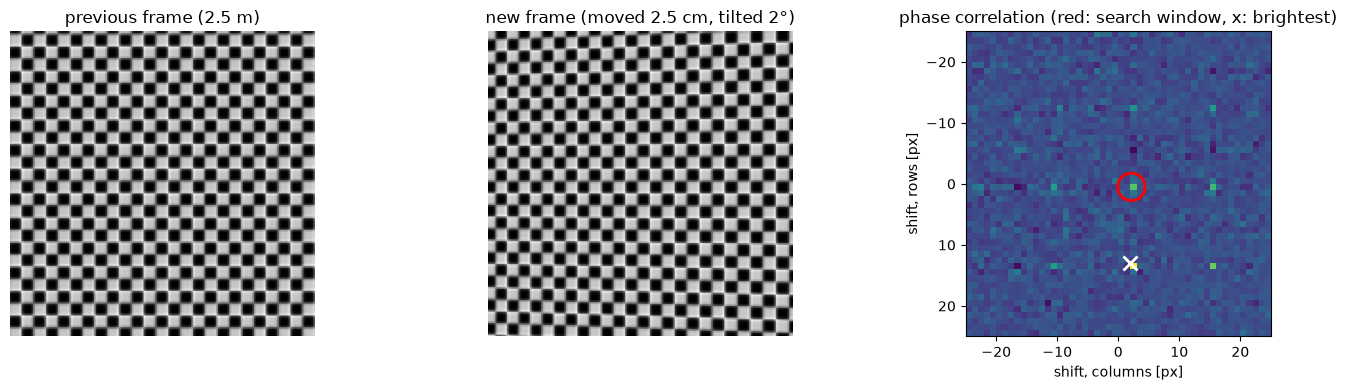

true velocity                        : (0.50, 0.10) m/s
brightest peak anywhere (no window)  : col +2, row +13 px -> (0.49, 8.11) m/s
search window around the prediction  : centre col +2.2, row +0.5 px, radius 2.2 px -> (0.50, 0.01) m/s


In [6]:
TRUE_V, PRED_V, H = np.array([0.5, 0.1]), np.array([0.4, 0.3]), 2.5
place([0.11, -0.05, H]); cam.prev = None
h0, _, g0, _ = cam.measure(data, (0, 0))                       # previous frame
q = np.zeros(4); mujoco.mju_axisAngle2Quat(q, np.array([0.0, 1.0, 0.0]), np.radians(2.0))
place([0.11 + TRUE_V[0] * sensing.CAM_PERIOD, -0.05 + TRUE_V[1] * sensing.CAM_PERIOD, H], q)
rot1 = data.cam_xmat[cam.cam_id].reshape(3, 3).copy()
h1, v, g1, _ = cam.measure(data, PRED_V)                       # new frame -> velocity (with search window)

corr = sensing.correlation_surface(g0, g1)
n = corr.shape[0]
moved = -PRED_V * sensing.CAM_PERIOD                           # where the old centre point should be now
guess = cam._pixel_of(rot1, np.array([moved[0], moved[1], -h1]))
radius = max(1.5, 0.35 * 0.2 * cam.focal / h1)
ky, kx = np.unravel_index(np.argmax(corr), corr.shape)         # brightest peak anywhere, no window
naive = ((kx + n / 2) % n - n / 2, (ky + n / 2) % n - n / 2)
d1 = cam._ray(rot1, *naive)
v_naive = -(h1 * d1[:2] / -d1[2]) / sensing.CAM_PERIOD         # same geometry, wrong peak

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(g0, cmap="gray"); ax[0].set_title("previous frame (2.5 m)"); ax[0].axis("off")
ax[1].imshow(g1, cmap="gray"); ax[1].set_title("new frame (moved 2.5 cm, tilted 2°)"); ax[1].axis("off")
ax[2].imshow(np.fft.fftshift(corr), cmap="viridis", extent=[-n / 2, n / 2, n / 2, -n / 2])
ax[2].add_patch(plt.Circle(guess, radius, fill=False, color="red", lw=2))
ax[2].plot(*naive, "wx", ms=10, mew=2)
ax[2].set_xlim(-25, 25); ax[2].set_ylim(25, -25)
ax[2].set_title("phase correlation (red: search window, x: brightest)"); ax[2].set_xlabel("shift, columns [px]"); ax[2].set_ylabel("shift, rows [px]")
plt.tight_layout(); plt.show()
print(f"true velocity                        : ({TRUE_V[0]:.2f}, {TRUE_V[1]:.2f}) m/s")
print(f"brightest peak anywhere (no window)  : col {naive[0]:+.0f}, row {naive[1]:+.0f} px -> ({v_naive[0]:.2f}, {v_naive[1]:.2f}) m/s")
print(f"search window around the prediction  : centre col {guess[0]:+.1f}, row {guess[1]:+.1f} px, radius {radius:.1f} px -> ({v[0]:.2f}, {v[1]:.2f}) m/s")
cam.close()

#### Steps 2-4: checks, Kalman filter, PID
**Sanity checks.** A height reading is dropped if it's outside 0.25-4 m, or if the camera points less than 60° below
the horizon (tilted too far, or lying on the floor after a crash). The filter also rejects any reading more than
5 standard deviations away from what it expects.

**Kalman filter.** It tracks position and velocity on each axis. Every 0.01 s it **predicts** forward using the
accelerometer (rotated into the world frame, gravity removed), then **corrects** with whatever readings arrived
that step. Each reading is weighted by its expected error, so more accurate sensors pull harder:

| Reading | Rate | Expected error (σ) | Corrects |
|---|---|---|---|
| Camera height | 20 Hz | 1 cm + 2 % of height (about 3.4 cm at 1.2 m) | height |
| Camera velocity | 20 Hz | 0.03 + 0.04 × height m/s (about 0.08 m/s at 1.2 m) | sideways and forward speed |
| Barometer | 20 Hz | 20 cm | height |
| GPS | 5 Hz | 30 cm sideways, 40 cm vertical | all three positions |

- **The camera dominates the height estimate.** It is trusted about 5× more than the barometer and 10× more than GPS
  height.
- **Horizontal position still depends on GPS.** The camera gives only sideways *velocity*. Better velocity keeps the
  position from drifting between GPS readings, so horizontal error halves rather than collapsing.
- **In the no_camera condition**, the filter is identical but never receives camera readings.

**PID.** It receives the filter's position and velocity in place of the true values and is otherwise unchanged.
Its attitude and rotation rates come straight from the simulator in every condition.

## 2. Run the experiment
140 flights: 20 perfect, 60 no_camera, 60 camera. Takes about 5 minutes; camera flights take about 4 s each because
of rendering and image processing. **Resumable:** if the computer shuts down, re-run this cell (or
`python experiment.py` in this folder). Finished flights are skipped and a half-written one is
flown again.

In [7]:
summary = E.run()

done: 0 flown, 140 already done -> data


## 3. The data
`data/summary.csv` has one row per flight. Each flight folder holds:
- `flight.csv`: 100 Hz log of true state, estimate, raw GPS, barometer and camera readings, motors, fault flag
- `flight.json`: settings and metrics
- `frames.npz`: the camera frames, camera seed 0 only, to keep the size down

In [8]:
summary = pd.read_csv(DATA / "summary.csv")
print(summary.shape)
summary[["flight_id", "condition", "noise_seed", "route", "loss", "crashed", "max_alt_loss", "min_z", "recovery_time",
         "mean_track_error", "final_dist_to_B", "est_z_rmse", "est_xy_rmse", "est_vel_rmse"]].head(8).round(3)

(140, 30)


,flight_id,condition,noise_seed,route,loss,crashed,max_alt_loss,min_z,recovery_time,mean_track_error,final_dist_to_B,est_z_rmse,est_xy_rmse,est_vel_rmse
0,perfect_s0_path1_loss00.0,perfect,0,path1,0.000,False,0.179,1.126,NaN,0.068,0.065,0.057,0.220,0.130
1,perfect_s0_path1_loss12.5,perfect,0,path1,0.125,False,0.172,1.160,0.17,0.088,0.002,0.030,0.218,0.133
2,perfect_s0_path1_loss25.0,perfect,0,path1,0.250,False,0.469,1.067,6.33,0.164,0.007,0.056,0.169,0.097
3,perfect_s0_path1_loss37.5,perfect,0,path1,0.375,False,0.882,0.779,7.37,0.304,0.003,0.024,0.142,0.087
4,perfect_s0_path1_loss50.0,perfect,0,path1,0.500,True,1.964,-0.006,NaN,1.206,1.527,0.058,0.334,0.194
5,perfect_s0_path2_loss00.0,perfect,0,path2,0.000,False,0.105,1.365,NaN,0.050,0.013,0.057,0.251,0.099
6,perfect_s0_path2_loss12.5,perfect,0,path2,0.125,False,0.141,1.397,5.67,0.069,0.006,0.031,0.090,0.034
7,perfect_s0_path2_loss25.0,perfect,0,path2,0.250,False,0.440,1.358,5.75,0.128,0.007,0.046,0.128,0.068


In [9]:
log = pd.read_csv(DATA / "camera_s0_path3_loss37.5" / "flight.csv")
print(f"{len(log)} rows x {len(log.columns)} columns:")
print(", ".join(log.columns))

1658 rows x 40 columns:
step, t, target_x, target_y, target_z, target_vx, target_vy, target_vz, pos_x, pos_y, pos_z, vel_x, vel_y, vel_z, tilt_deg, command_1, command_2, command_3, command_4, applied_1, applied_2, applied_3, applied_4, fault_active, dist_to_B, track_error, est_x, est_y, est_z, est_vx, est_vy, est_vz, gps_x, gps_y, gps_z, baro_z, cam_h, cam_vx, cam_vy, cam_frame


## 4. Analysis
### 4a. How well does each condition know where the drone is?
Estimation error (estimate minus truth, RMS over the flight), averaged over flights. The perfect condition's PID
ignores its estimate; its row shows what the IMU + GPS + barometer filter alone achieves.

In [10]:
est = summary[summary.loss < 0.45].groupby("condition")[["est_z_rmse", "est_xy_rmse", "est_vel_rmse"]].mean()
est.columns = ["height error [m]", "horizontal error [m]", "velocity error [m/s]"]
est.loc[["no_camera", "camera"]].round(3)

,height error [m],horizontal error [m],velocity error [m/s]
condition,,,
no_camera,0.050,0.191,0.102
camera,0.009,0.090,0.051


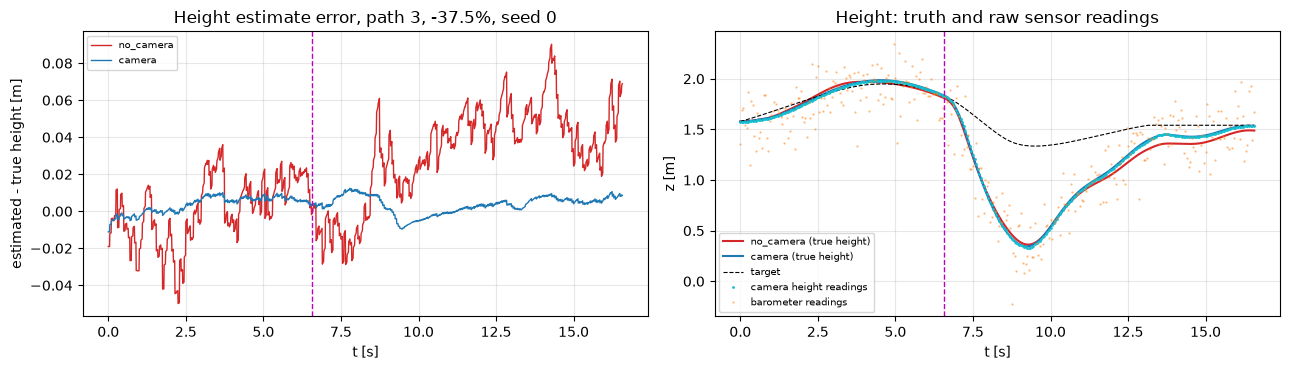

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for cond in ("no_camera", "camera"):
    lg = pd.read_csv(DATA / f"{cond}_s0_path3_loss37.5" / "flight.csv")
    ax[0].plot(lg.t, lg.est_z - lg.pos_z, color=COND_COLOURS[cond], lw=1, label=cond)
    ax[1].plot(lg.t, lg.pos_z, color=COND_COLOURS[cond], lw=1.5, label=f"{cond} (true height)")
ax[1].plot(lg.t, lg.target_z, "k--", lw=0.8, label="target")
c = lg[np.isfinite(lg.cam_h)]
ax[1].plot(c.t, c.cam_h, ".", ms=2, color="tab:cyan", label="camera height readings")
ax[1].plot(lg.t, lg.baro_z, ".", ms=1.5, color="tab:orange", alpha=0.4, label="barometer readings")
for a in ax:
    a.axvline(6.58, color="m", ls="--", lw=1); a.grid(alpha=0.3); a.legend(fontsize=7)
ax[0].set(xlabel="t [s]", ylabel="estimated - true height [m]", title="Height estimate error, path 3, -37.5%, seed 0")
ax[1].set(xlabel="t [s]", ylabel="z [m]", title="Height: truth and raw sensor readings")
plt.tight_layout()

### 4b. Recovery from the fault
Crashes, largest drop, lowest point and recovery time, per condition and loss level (means over routes and seeds).

In [12]:
g = summary.groupby(["loss", "condition"]).agg(
    flights=("crashed", "size"), crashed=("crashed", "sum"), drop_m=("max_alt_loss", "mean"),
    lowest_m=("min_z", "mean"), worst_lowest_m=("min_z", "min"), recovery_s=("recovery_time", "mean"))
g.round(3)

flights  crashed  drop_m  lowest_m  worst_lowest_m  recovery_s
loss  condition                                                                
0.000 camera          12        0   0.134     1.250           1.112         NaN
      no_camera       12        0   0.163     1.227           0.997         NaN
      perfect          4        0   0.137     1.247           1.126         NaN
0.125 camera          12        0   0.206     1.225           1.080       4.088
      no_camera       12        0   0.229     1.203           0.953       3.584
      perfect          4        0   0.203     1.222           1.088       3.598
0.250 camera          12        0   0.506     1.041           0.751       5.979
      no_camera       12        0   0.500     1.042           0.632       6.132
      perfect          4        0   0.507     1.034           0.753       6.208
0.375 camera          12        0   0.926     0.676           0.320       7.688
      no_camera       12        0   0.908     0.656           0.301       7.691
      perfect          4        0   0.924     0.674           0.337       8.010
0.500 camera          12       12   1.890    -0.003          -0.017         NaN
      no_camera       12       12   1.890    -0.004          -0.011         NaN
      perfect          4        4   1.891    -0.004          -0.006         NaN

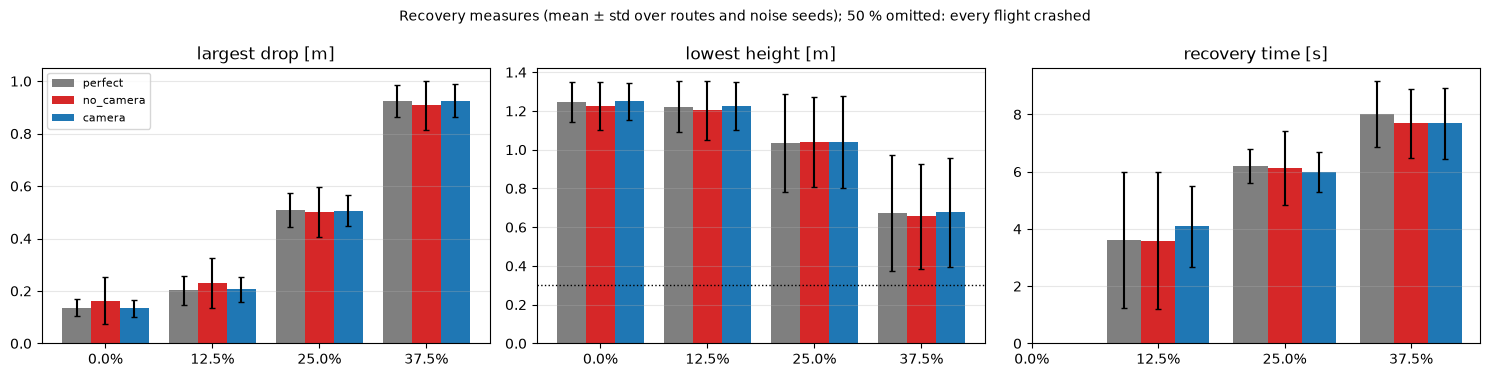

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
losses = sorted(summary.loss.unique())[:-1]  # survivable levels
w = 0.27
for i, cond in enumerate(("perfect", "no_camera", "camera")):
    s = summary[(summary.condition == cond) & (summary.loss < 0.45)].groupby("loss")
    x = np.arange(len(losses)) + (i - 1) * w
    for a, col in zip(ax, ["max_alt_loss", "min_z", "recovery_time"]):
        a.bar(x, s[col].mean(), w, yerr=s[col].std(), capsize=2, color=COND_COLOURS[cond], label=cond)
for a, t in zip(ax, ["largest drop [m]", "lowest height [m]", "recovery time [s]"]):
    a.set_xticks(range(len(losses)), [f"{l:.1%}" for l in losses]); a.set_title(t); a.grid(alpha=0.3, axis="y")
ax[1].axhline(config.CRASH_MIN_Z, color="k", ls=":", lw=1)
ax[0].legend(fontsize=8)
plt.suptitle("Recovery measures (mean ± std over routes and noise seeds); 50 % omitted: every flight crashed", fontsize=10)
plt.tight_layout()

**Paired comparison.** For each of the 48 survivable (route, loss, seed) cases: camera minus no_camera, same noise.

In [14]:
a = summary[summary.condition == "no_camera"].set_index(["noise_seed", "route", "loss"])
b = summary[summary.condition == "camera"].set_index(["noise_seed", "route", "loss"])
surv = ~(a.crashed | b.crashed)
rows = []
for col, better in [("max_alt_loss", "lower"), ("min_z", "higher"), ("recovery_time", "lower"),
                    ("mean_track_error", "lower"), ("final_dist_to_B", "lower"), ("est_z_rmse", "lower")]:
    diff = (b[col] - a[col])[surv].dropna()
    wins = (diff < 0).sum() if better == "lower" else (diff > 0).sum()
    rows.append({"measure": col, "mean difference (camera - no_camera)": round(diff.mean(), 4),
                 "camera better in": f"{wins}/{len(diff)}"})
pd.DataFrame(rows).set_index("measure")

,mean difference (camera - no_camera),camera better in
measure,,
max_alt_loss,-0.0072,24/48
min_z,0.0160,23/48
recovery_time,0.0288,18/32
mean_track_error,-0.1090,44/48
final_dist_to_B,-0.2188,47/48
est_z_rmse,-0.0407,48/48


### 4c. How repeatable is the outcome?
The same flight flown with 3 different noise draws: how much does the lowest point vary? And how far is it from the
perfect-state flight?

In [15]:
perf = summary[summary.condition == "perfect"].set_index(["route", "loss"])
rows = []
for cond in ("no_camera", "camera"):
    x = summary[(summary.condition == cond) & (summary.loss < 0.45)]
    sd = x.groupby(["route", "loss"]).min_z.std()
    xi = x.set_index(["route", "loss"])
    dev = (xi.min_z - perf.min_z.reindex(xi.index)).abs()
    rows.append({"condition": cond, "spread of lowest point across seeds, mean std [m]": round(sd.mean(), 3),
                 "largest spread [m]": round(sd.max(), 3),
                 "mean |lowest point - perfect| [m]": round(dev.mean(), 3), "worst [m]": round(dev.max(), 3)})
pd.DataFrame(rows).set_index("condition")

,"spread of lowest point across seeds, mean std [m]",largest spread [m],mean |lowest point - perfect| [m],worst [m]
condition,,,,
no_camera,0.073,0.139,0.058,0.212
camera,0.014,0.035,0.012,0.054


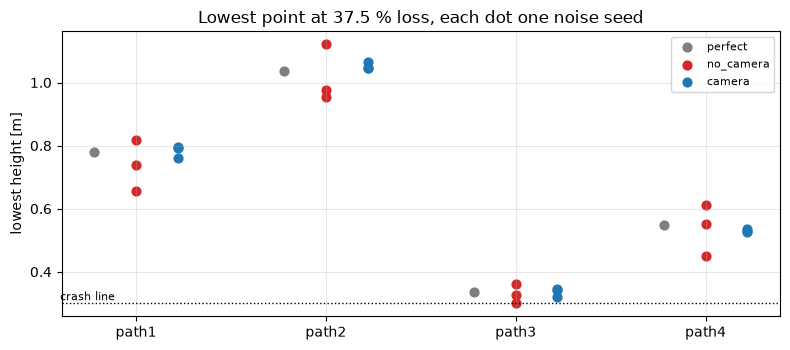

In [16]:
x37 = summary[summary.loss == 0.375]
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, route in enumerate(sorted(x37.route.unique())):
    for j, cond in enumerate(("perfect", "no_camera", "camera")):
        v = x37[(x37.route == route) & (x37.condition == cond)].min_z
        ax.scatter(np.full(len(v), i + (j - 1) * 0.22), v, color=COND_COLOURS[cond], s=40, label=cond if i == 0 else None)
ax.axhline(config.CRASH_MIN_Z, color="k", ls=":", lw=1); ax.text(-0.4, 0.31, "crash line", fontsize=8)
ax.set_xticks(range(4), sorted(x37.route.unique())); ax.set_ylabel("lowest height [m]")
ax.set_title("Lowest point at 37.5 % loss, each dot one noise seed"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()

### 4d. Flying accuracy
Mean distance to the moving target point, and the final distance to B.

In [17]:
acc = summary[summary.loss < 0.45].groupby("condition")[["mean_track_error", "final_dist_to_B", "cmd_smoothness"]].mean()
acc.columns = ["mean distance to target [m]", "final distance to B [m]", "command jumpiness [N/step]"]
acc.loc[["perfect", "no_camera", "camera"]].round(3)

,mean distance to target [m],final distance to B [m],command jumpiness [N/step]
condition,,,
perfect,0.150,0.021,0.005
no_camera,0.311,0.326,0.009
camera,0.202,0.107,0.006


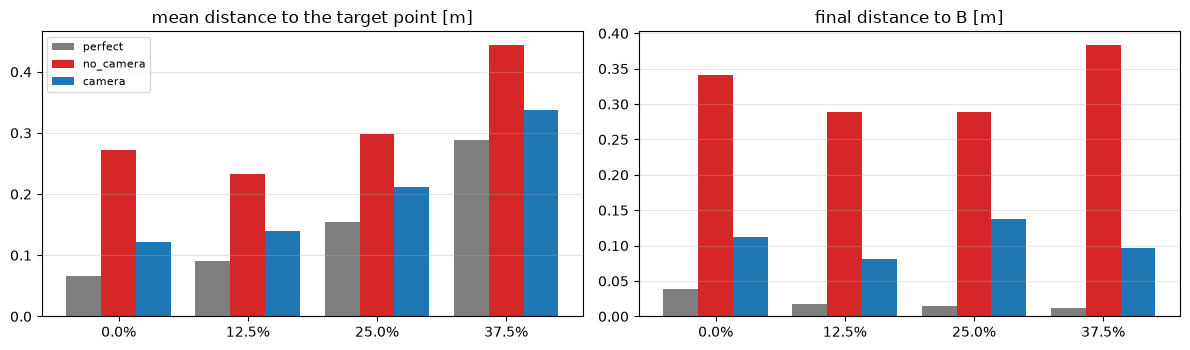

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for k, col in enumerate(["mean_track_error", "final_dist_to_B"]):
    for i, cond in enumerate(("perfect", "no_camera", "camera")):
        s = summary[(summary.condition == cond) & (summary.loss < 0.45)].groupby("loss")[col]
        ax[k].bar(np.arange(len(losses)) + (i - 1) * w, s.mean(), w, color=COND_COLOURS[cond], label=cond)
    ax[k].set_xticks(range(len(losses)), [f"{l:.1%}" for l in losses]); ax[k].grid(alpha=0.3, axis="y")
ax[0].set_title("mean distance to the target point [m]"); ax[1].set_title("final distance to B [m]"); ax[0].legend(fontsize=8)
plt.tight_layout()

## 5. Results
**Crashes: no difference.** All 12 flights per condition at 50 % loss crashed, as did all 4 perfect-state ones; the
loss is beyond the 45.8 % physical limit at a fixed heading. No flight crashed at 0-37.5 % in any condition.

**Average recovery: no meaningful difference.** Over the 48 paired survivable cases, camera minus no_camera:
- largest drop: −0.007 m on average; the camera is better in 24 of 48 cases, a coin flip
- lowest point: +0.016 m; better in 23 of 48
- recovery time: +0.03 s on average; faster in 18 of the 32 cases that have a recovery time

Both match the perfect-state flights on average, with drops of about 0.20 / 0.51 / 0.92 m at 12.5 / 25 / 37.5 %.

**Repeatability: the camera makes recovery much more predictable.** The lowest point varies by 0.073 m (std across
seeds) without the camera and 0.014 m with it, five times less. Its distance from the perfect-state result falls
from 0.058 m (worst 0.21 m) to 0.013 m (worst 0.05 m). At 37.5 % on path 3, the camera drone bottomed out at
0.32-0.34 m, close to perfect (0.337). Without the camera it ranged from 0.30 to 0.36 m: one seed ended 1 cm above
the crash line, another 2.5 cm higher than perfect, purely from sensor noise.

**Accuracy: clearly better with the camera.**

| | perfect | no_camera | camera |
|---|---|---|---|
| height estimate error | - | 0.050 m | **0.010 m** |
| horizontal estimate error | - | 0.19 m | **0.09 m** |
| velocity estimate error | - | 0.10 m/s | **0.05 m/s** |
| mean distance to the target | 0.15 m | 0.31 m | **0.20 m** |
| final distance to B | 0.02 m | 0.33 m | **0.11 m** |

The camera is better on final distance in 47 of 48 paired cases, tracking in 44 of 48, height estimate in 48 of 48,
and gives smoother motor commands in 48 of 48. Camera height readings were accurate to 5 mm (median RMS) in flight;
camera velocity to about 0.16 m/s.

## Conclusion
**The camera makes the drone fly more accurately and recover more *predictably*, but not more *strongly*.**
- How far a drone falls after a motor fault is set by the thrust it has left and how the PID responds. Better
  position knowledge doesn't create thrust, and the accelerometer already reports the sudden sag to the estimator
  within milliseconds. So the average drop, lowest point, recovery time and crash count are unchanged.
- What the camera removes is noise-driven luck. Without it, the same flight can end several centimetres higher or
  lower depending on GPS and barometer noise. With it, every run lands within a few centimetres of the
  perfect-information result. Near the crash line, where path 3 at 37.5 % flies, that consistency is a real safety
  margin.
- It also roughly triples the accuracy of reaching B (0.33 → 0.11 m) and halves the tracking error.

**Limitations**
- The scene is ideal for this camera: a flat, evenly lit, high-contrast checkerboard. Real floors would give worse
  height readings.
- Attitude was assumed known in every condition.
- The sensor noise levels (GPS 0.3/0.4 m, barometer 0.2 m) decide how much the camera can add. Better GPS or
  barometer readings would shrink the camera's advantage.
- The controller is the same PID in every condition. A controller that *uses* the better estimate differently, for
  example a learned policy or a fault estimator, might turn better knowledge into better recovery. This experiment
  doesn't test that.
- 3 noise seeds per condition; the paired design makes the camera comparisons sharper than that number suggests.

## Run record
Written by the code: real start and end times, versions and code hashes (`data/manifest.json`).

In [19]:
m = json.loads((DATA / "manifest.json").read_text())
print("git revision:", m.get("git_revision"), "| MuJoCo", m["versions"]["mujoco"], "| Python", m["python"])
for s in m["sessions"]:
    print(f"session {s['started']} -> {s.get('finished', 'interrupted')}: flown {len(s['flown'])}, skipped {len(s['skipped'])}")

git revision: 02e6e60 | MuJoCo 3.16.0 | Python 3.13.9
session 2026-11-05T21:19:11 -> 2026-11-05T21:23:16: flown 140, skipped 0
session 2026-11-05T21:23:32 -> 2026-11-05T21:23:32: flown 0, skipped 140
session 2026-11-05T22:27:06 -> 2026-11-05T22:30:58: flown 140, skipped 0
session 2026-11-05T22:31:59 -> 2026-11-05T22:31:59: flown 0, skipped 140
session 2026-11-05T23:35:48 -> 2026-11-05T23:35:49: flown 0, skipped 140
